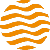

In [1]:
from IPython.display import Image, display
display(Image(filename='../../docs/gerics.png'))

![](../../docs/gerics.png)

# GERICS Climate factsheet Africa

## Code to plot the climate stripes 


*Climate stripes* have been established by Professor Ed Hawkins, Universität Reading in 2018.

The data base is ERA5 average over each African country.
Data source: "Hersbach, H, Bell, B, Berrisford, P, et al. The ERA5 global reanalysis. Q J R Meteorol Soc. 2020; 146: 1999– 2049. https://doi.org/10.1002/qj.3803". 

**Katharina Bülow**, Climate Service Center Germany (GERICS), Helmholtz-Zentrum hereon GmbH, Email: katharina.buelow@hereon.de


In [2]:
import os

import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import ListedColormap

In [3]:
import warnings
warnings.filterwarnings('ignore')

#### Organization of directories and input and output files

In [11]:
datadir="/work/ch0636/g300047/cicles/climate_fact_data/spavg_era5"
file="climdexERA5_TG_year_weighted_means.csv"
inputT=os.path.join(datadir,file)
outdir="/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/ERA5-Plots-climatestripes"
if not os.path.exists(outdir):
    os.makedirs(outdir)

#### Select country:

In [22]:
# Country selection
#country = "Ivory Coast"
#country = "Togo"
country = "Burkina Faso"

region = country.replace(" ", "_")
plotname = "Climatestripes_deviation_to_1981_2010_ERA5_" + region+".png"
figure = os.path.join(outdir, plotname)

In [23]:
def select_region(df, country):
    return df.loc[(df["region"].isin([country]))]

In [24]:
def deviation(df):
    df["time"] = pd.to_datetime(df["time"])
    df_ = df.copy()
    start = "1991-01-01"
    end = "2020-12-31"

    mask = (df_["time"] >= start) & (df_["time"] <= end)
    
    df_new = df_[mask]
    hist = df_new["value"].mean()

    df["Temperature anomaly [°C]"] = df["value"] - hist

    # hübscher für die Graphik:
    df["year"] = pd.DatetimeIndex(df["time"]).year

    return df

In [25]:
# Read ERA5 data and calculate deviations:
df = pd.read_csv(inputT)
dfr = select_region(df, country)
dfn = deviation(dfr)

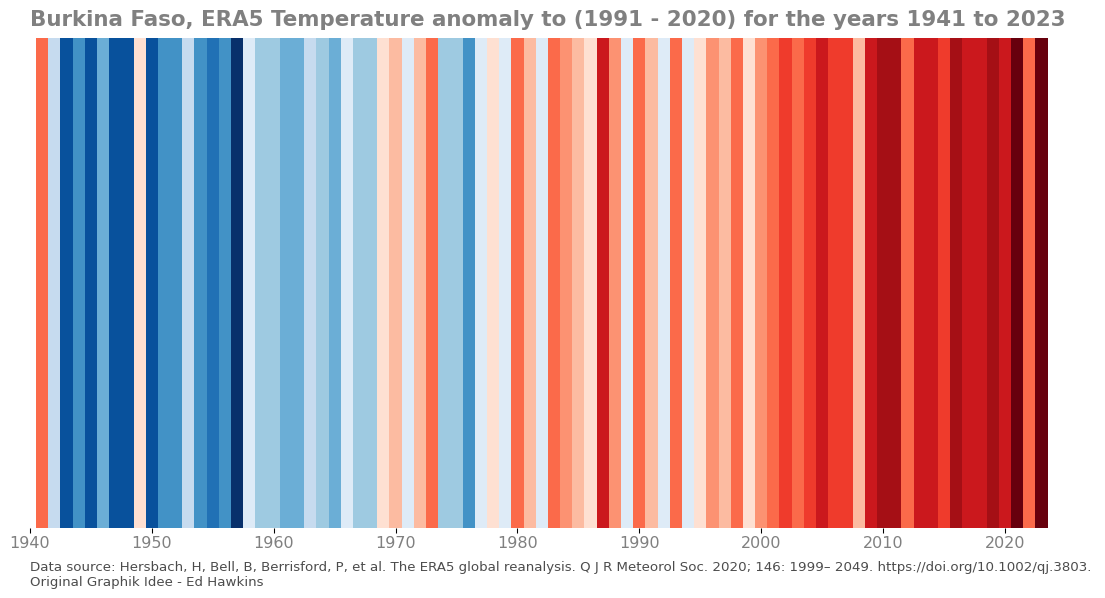

In [26]:
# Create Figure:
#
# SOURCE:
# plotting routine: https://towardsdatascience.com/visualizing-climate-change-a-step-by-step-guide-to-reproduce-climate-stripes-with-python-ea1d440e8e8d

fig, ax = plt.subplots(figsize=(13.33, 7.5), dpi=96)

# Farben - 8 blau und 8 rot
cmap = ListedColormap(
    [
        "#08306b",
        "#08519c",
        "#2171b5",
        "#4292c6",
        "#6baed6",
        "#9ecae1",
        "#c6dbef",
        "#deebf7",
        "#fee0d2",
        "#fcbba1",
        "#fc9272",
        "#fb6a4a",
        "#ef3b2c",
        "#cb181d",
        "#a50f15",
        "#67000d",
    ]
)

# lineare Normalizirung der Daten in das [0.0, 1.0] Interval
norm = mpl.colors.Normalize(
    dfn["Temperature anomaly [°C]"].min(), dfn["Temperature anomaly [°C]"].max()
)

# Darstellen der Balken
bar = ax.bar(
    dfn["year"],
    1,
    color=cmap(norm(dfn["Temperature anomaly [°C]"])),
    width=1,
    zorder=2,
)

# Entfernen der *spines*
ax.spines[["top", "left", "bottom", "right"]].set_visible(False)

# Format für y-axis label and tick labels
ax.set_ylabel("", fontsize=12, labelpad=10)
ax.set_yticks([])
ax.set_ylim([0, 1])

# Format für x-axis label and tick labels
ax.set_xlabel("", fontsize=12, labelpad=10)
ax.xaxis.set_tick_params(
    pad=2,
    labelbottom=True,
    bottom=True,
    labelsize=12,
    labelrotation=0,
    labelcolor="grey",
)
ax.set_xlim([dfn["year"].min() - 1, dfn["year"].max() + 1])

# Titel eingeben:
ax.set_title(
    country + ", ERA5 Temperature anomaly to (1991 - 2020) for the years 1941 to 2023",
    loc="left",
    color="grey",
    fontweight="bold",
    size=16,
    pad=10,
)

# Datenquelle: Text eingeben
ax.text(
    x=0.1,
    y=0.12,
    s="Data source: Hersbach, H, Bell, B, Berrisford, P, et al. The ERA5 global reanalysis. Q J R Meteorol Soc. 2020; 146: 1999– 2049. https://doi.org/10.1002/qj.3803. \nOriginal Graphik Idee - Ed Hawkins",

    transform=fig.transFigure,
    ha="left",
    fontsize=10,
    alpha=0.7,
)

# Anpassen der Ränder und Abstände
plt.subplots_adjust(
    left=0.1, right=None, top=None, bottom=0.2, wspace=None, hspace=None
)

# Weißer Hintergrund
fig.patch.set_facecolor("white")
ax.patch.set_facecolor("white")
plt.savefig(figure, dpi=1200)

In [10]:
figure

'/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/ERA5-Plots-climatestripes/Climatestripes_deviation_to_1981_2010_ERA5_Ivory_Coast.png'